In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = pd.read_csv(r"C:\Users\Nelson\Desktop\IronHack\Labs\Lab9 - Univariate\lab-eda-univariate\Data\amz_uk_price_prediction_dataset.csv")


In [2]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


## Part 1

In [3]:
# Fequency Table

df['category'].value_counts()


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [4]:
# Top 5 most listed products

df['category'].value_counts(ascending=False).head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

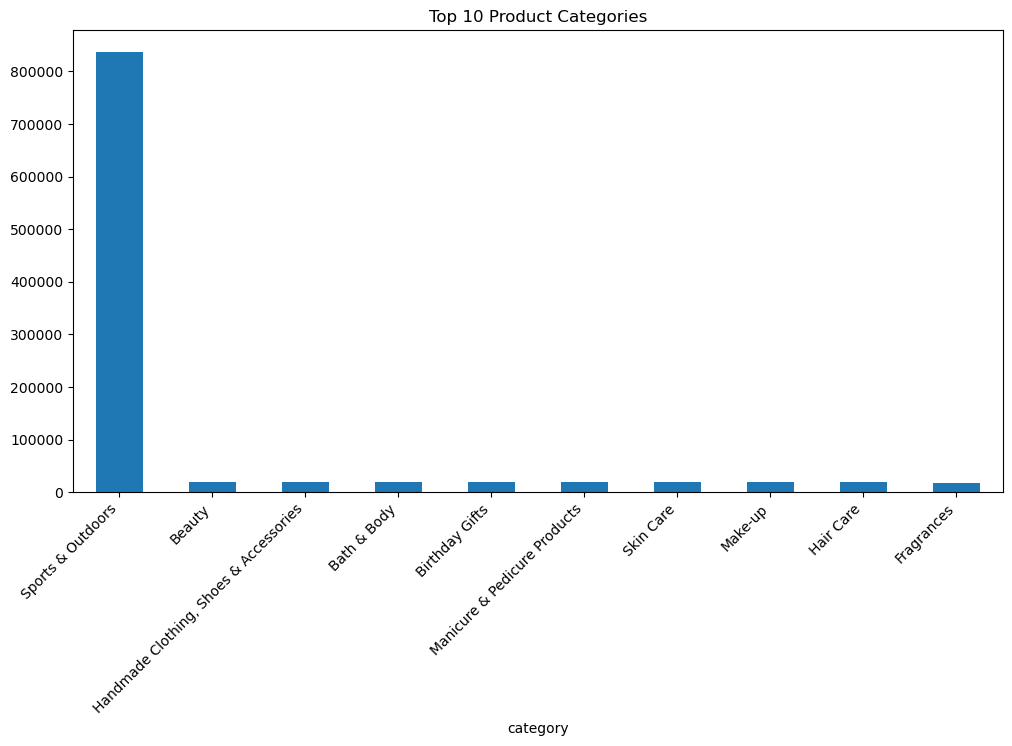

In [5]:
# Bar Chart

df10 = df["category"].value_counts().head(10)

df10.plot(kind="bar", figsize=(12,6))
plt.xticks(rotation=45, ha="right")
plt.title("Top 10 Product Categories")
plt.show()


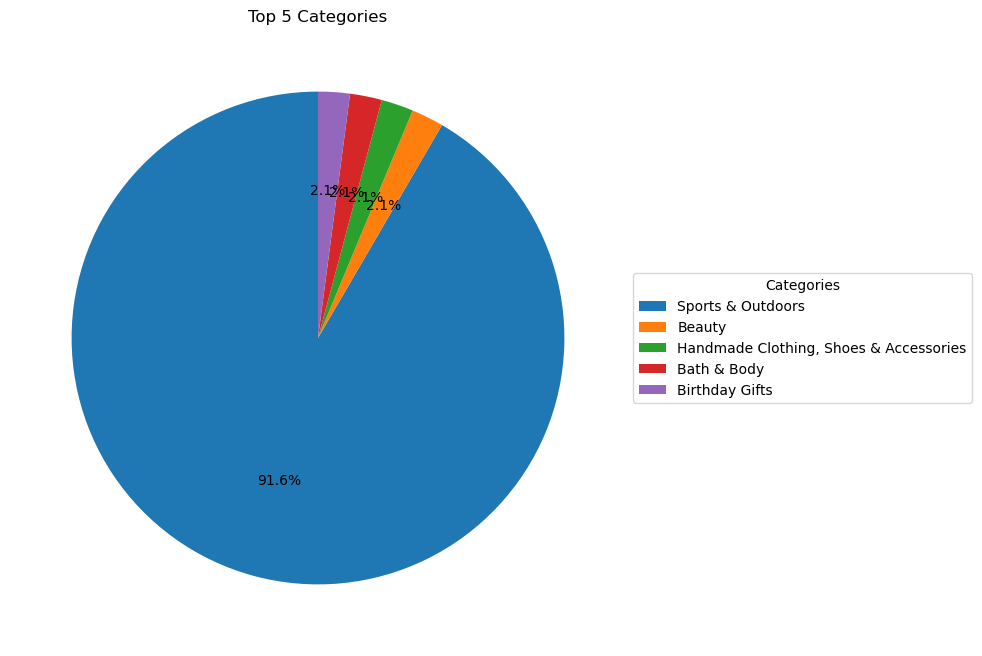

In [6]:
top5 = df["category"].value_counts().head(5)

top5.plot(
    kind="pie",
    autopct="%1.1f%%",
    labels=None,
    figsize=(8,8),
    startangle=90
)

plt.title("Top 5 Categories")
plt.ylabel("")
plt.legend(top5.index, title="Categories", loc="center left", bbox_to_anchor=(1,0.5))
plt.show()

## Part 2

In [7]:
# Calculate the mean, median, and mode

print(f"Mean: {df['price'].mean()}.")
print(f"Median: {df['price'].median()}.")
print(f"Mode: {df['price'].mode()}.")

Mean: 89.24380943923661.
Median: 19.09.
Mode: 0    9.99
Name: price, dtype: float64.


### What's the average price point of products listed? How does this compare with the most common price point (mode)?

The mean product price is 19.99, whereas the modal price is 9.99. Since the mean is higher than the mode, this suggests a right-skewed price distribution, where a smaller number of expensive products pull the average upward.


In [8]:
# Determine the variance, standard deviation, range, and interquartile range for product price

variance = df["price"].var()
std_dev = df["price"].std()
price_range = df["price"].max() - df["price"].min()
iqr = df["price"].quantile(0.75) - df["price"].quantile(0.25)

print(f"Variance: {variance:.3f}")
print(f"Standard Deviation: {std_dev:.3f}")
print(f"Range: {price_range:.3f}")
print(f"IQR: {iqr:.3f}")

Variance: 119445.485
Standard Deviation: 345.609
Range: 100000.000
IQR: 36.000


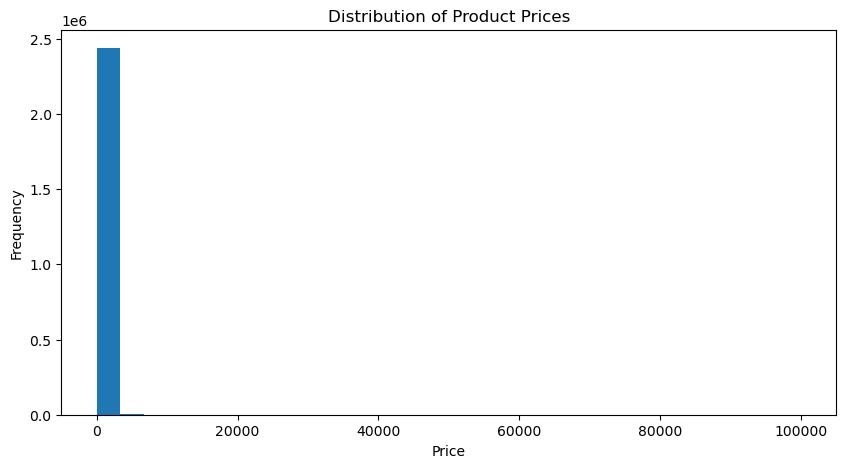

In [9]:
df["price"].plot(kind="hist", bins=30, figsize=(10,5))
plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.show()

## Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..

Most products fall within lower price ranges. The histogram is difficult to interpret because a small number of very expensive products stretch the scale. Filtering extreme values or using a log scale improves readability.

## Part 3

In [10]:
# Calculate the mean, median, and mode for the rating of products.

print(f"Mean: {df['stars'].mean():.3f}.")
print(f"Median: {df['stars'].median()}.")
print(f"Mode: {df['stars'].mode()}.")

Mean: 2.153.
Median: 0.0.
Mode: 0    0.0
Name: stars, dtype: float64.


Since both the median and mode are 0, this suggests that many products have not been rated by customers. Therefore, these values do not accurately reflect customer rating tendencies, so it is more appropriate to focus on reviewed products only.

In [ ]:
# Calculate the mean, median, and mode for the rating of products with review.

In [11]:
df_review = df [df['stars'] != 0]

print(f"Mean: {df_review['stars'].mean():.3f}.")
print(f"Median: {df_review['stars'].median()}.")
print(f"Mode: {df_review['stars'].mode()}.")


Mean: 4.319.
Median: 4.4.
Mode: 0    4.5
Name: stars, dtype: float64.


### We can now see that most reviews are positive. The average rating is 4.32 stars, and 4.5 stars is the most common rating.

In conclusion, many products have no ratings, but when customers do leave reviews, the overall feedback is very positive.

We can now see that most reviews are positive. The average rating is 4.32 stars, and 4.5 stars is the most common rating.

In conclusion, many products have no ratings, but when customers do leave reviews, the overall feedback is very positive.


### Measures of Dispersion:

- Determine the variance, standardeviation, and interquartile range of product
  

In [12]:
# I will use without the rate 0

variance = df_review["stars"].var()
std_dev = df_review["stars"].std()
price_range = df_review["stars"].max() - df_review["stars"].min()
iqr = df_review["stars"].quantile(0.75) - df_review["stars"].quantile(0.25)

print(f"Variance: {variance:.3f}")
print(f"Standard Deviation: {std_dev:.3f}")
print(f"Range: {price_range:.3f}")
print(f"IQR: {iqr:.3f}")

Variance: 0.308
Standard Deviation: 0.555
Range: 4.000
IQR: 0.500


- Are the ratings consistent, or is there a wide variation in customer feedback?

The variation in ratings is limited, which suggests that customer feedback is relatively consistent. Ratings are given on a scale from 1 to 5 stars, but the low standard deviation and an IQR of 0.5 indicate that most reviews are concentrated within a narrow range.

### Shape of the Distribution:

- Calculate the skewness and kurtosis for the rating column.

In [13]:
# I will use only the reviewed

skewness = df_review["stars"].skew()
kurtosis = df_review["stars"].kurt()

print(f"Skewness: {skewness:.3f}")
print(f"Kurtosis: {kurtosis:.3f}")


Skewness: -2.380
Kurtosis: 9.782


- Are the ratings normally distributed, or do they lean towards higher or lower values?

In [14]:
# The ratings lean strongly toward higher values, not a normal bell-shaped distribution.